# 01 · Exploración de UBFC-rPPG

Objetivo: entender el formato del ground truth y su calidad antes de construir el pipeline.

- Qué trae `ground_truth.txt` y si hay referencia respiratoria (decisión D4).
- Regularidad de los timestamps (justifica remuestrear con `rppg.dsp.resample`).
- Confiabilidad de la HR que reporta el oxímetro frente a la HR estimada desde su PPG con el mismo estimador que usará el rPPG.

La lógica vive en `rppg`; esta notebook solo la usa y grafica.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rppg.data.ubfc import UBFCrPPG
from rppg.dsp.filters import bandpass
from rppg.dsp.resample import resample_uniform
from rppg.dsp.spectral import estimate_rate, power_spectrum

DATA_ROOT = "../data/raw"
FS = 30.0
HR_BAND = (0.7, 4.0)
HR_WINDOW_S, HR_STEP_S = 10, 1  # D3

ds = UBFCrPPG(DATA_ROOT)
subjects = ds.subjects()
print(f"{len(subjects)} subjects available:", subjects)

30 subjects available: ['subject1', 'subject3', 'subject4', 'subject10', 'subject11', 'subject12', 'subject13', 'subject14', 'subject15', 'subject16', 'subject17', 'subject18', 'subject20', 'subject22', 'subject23', 'subject24', 'subject25', 'subject26', 'subject27', 'subject30', 'subject31', 'subject32', 'subject33', 'subject34', 'subject35', 'subject36', 'subject37', 'subject38', 'subject39', 'subject40']


## 1. Formato y duración

In [2]:
rows = []
for s in subjects:
    gt = ds.ground_truth(s)
    dt = np.diff(gt.t)
    rows.append({
        "subject": s,
        "frames": len(gt.t),
        "duration_s": gt.t[-1] - gt.t[0],
        "fps_mean": (len(gt.t) - 1) / (gt.t[-1] - gt.t[0]),
        "dt_max_ms": 1e3 * dt.max(),
        "gaps_over_0.5s": int((dt > 0.5).sum()),
        "device_hr_dropout_frac": float((gt.hr_device < 30).mean()),
    })
summary = pd.DataFrame(rows).set_index("subject")
summary.round(2)

,frames,duration_s,fps_mean,dt_max_ms,gaps_over_0.5s,device_hr_dropout_frac
subject,,,,,,
subject1,1547,52.69,29.34,223.0,0,0.00
subject3,1801,60.93,29.54,239.0,0,0.00
subject4,1368,46.23,29.57,157.0,0,0.00
subject10,2024,67.72,29.87,116.0,0,0.00
subject11,2031,68.38,29.69,135.0,0,0.21
subject12,1989,68.40,29.07,112.0,0,0.00
subject13,2018,67.72,29.78,163.0,0,0.00
subject14,1993,67.87,29.35,58.0,0,0.00
subject15,2020,68.27,29.57,878.0,1,0.00


Observaciones:

- Tres filas por archivo: PPG del oxímetro, HR del oxímetro y timestamps. **No hay señal respiratoria.**
- Videos de ~1 min (no ~2 min). Algunos sujetos a ~23 fps.
- Hay saltos de hasta ~1 s sin frames: se remuestrea usando timestamps y se marcan inválidas las muestras dentro de huecos > 0,5 s.

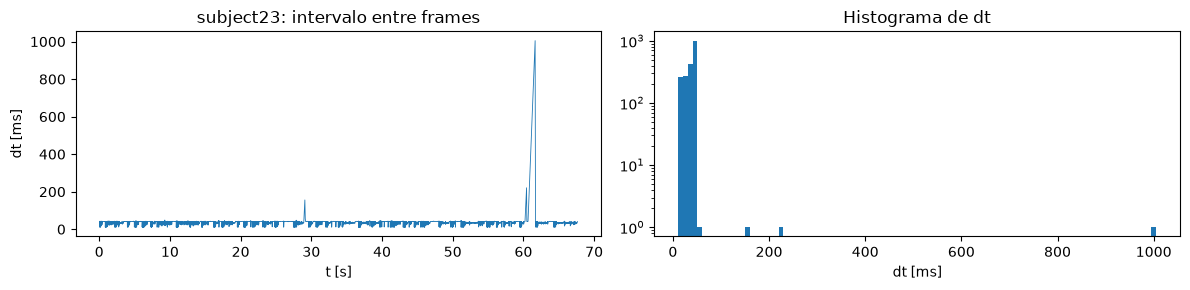

In [3]:
s = "subject23"
gt = ds.ground_truth(s)
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].plot(gt.t[1:], 1e3 * np.diff(gt.t), lw=0.6)
ax[0].set(title=f"{s}: intervalo entre frames", xlabel="t [s]", ylabel="dt [ms]")
ax[1].hist(1e3 * np.diff(gt.t), bins=100, log=True)
ax[1].set(title="Histograma de dt", xlabel="dt [ms]")
plt.tight_layout()

## 2. HR del oxímetro vs. HR desde la PPG

La HR que reporta el dispositivo tiene cortes (valores ~1 bpm). La referencia se calcula aplicando a la PPG **el mismo** estimador espectral que al rPPG.

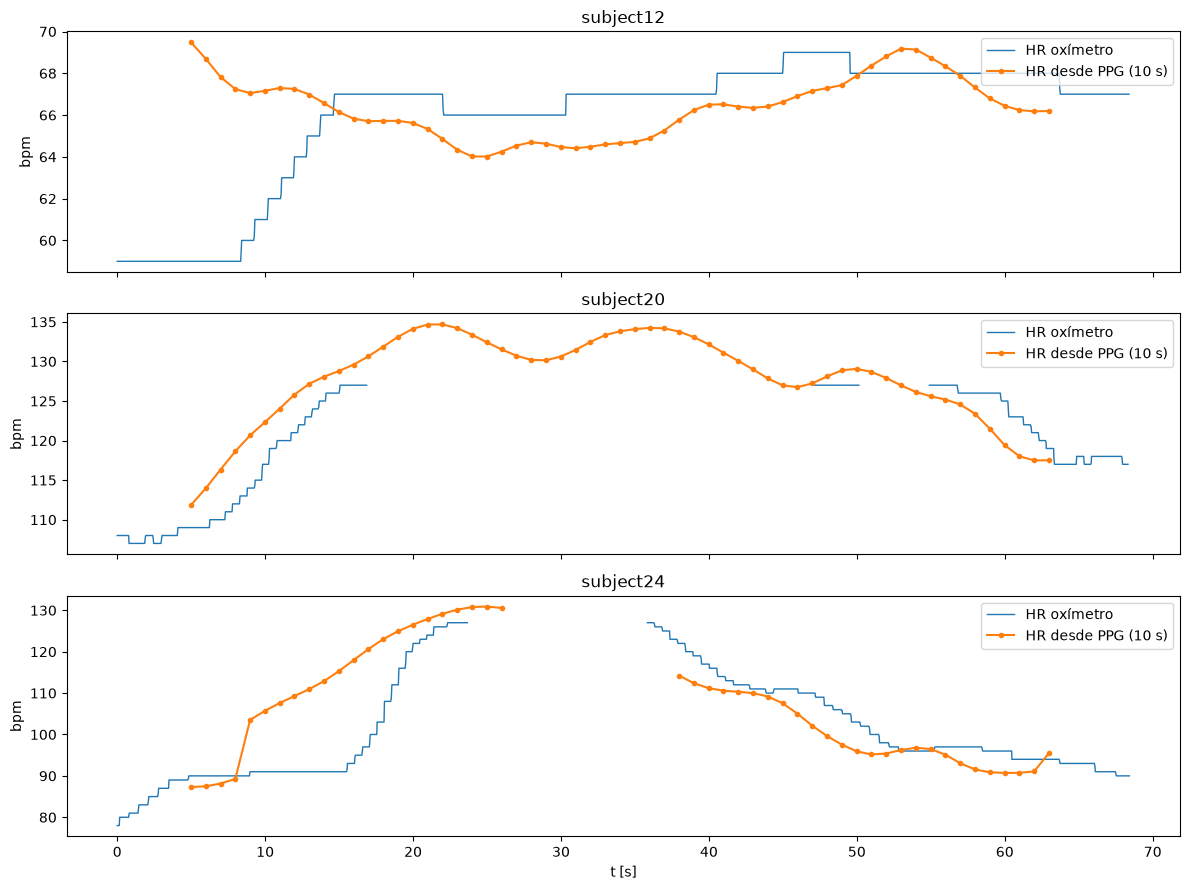

In [4]:
def reference_hr(gt):
    u = resample_uniform(gt.t, gt.ppg, FS, max_gap_s=0.5)
    y = bandpass(u.x, FS, *HR_BAND)
    return u, y, estimate_rate(y, FS, HR_BAND, HR_WINDOW_S, HR_STEP_S, valid=u.valid, nfft=4096)

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, s in zip(axes, ["subject12", "subject20", "subject24"]):
    gt = ds.ground_truth(s)
    _, _, est = reference_hr(gt)
    ax.plot(gt.t, np.where(gt.hr_device > 30, gt.hr_device, np.nan), label="HR oxímetro", lw=1)
    ax.plot(est.t_center + gt.t[0], est.rate_per_min, "o-", ms=3, label="HR desde PPG (10 s)")
    ax.set(title=s, ylabel="bpm")
    ax.legend(loc="upper right")
axes[-1].set_xlabel("t [s]")
plt.tight_layout()

- `subject12`: HR estable, ambas referencias coinciden.
- `subject20`: el oxímetro se corta en la mitad del video; la PPG sigue siendo utilizable.
- `subject24`: HR muy variable dentro del video (CV de intervalos entre latidos ≈ 0,2). Las dos referencias difieren varios bpm.

Conclusión: la elección de referencia mueve el MAE en el orden de ~3 bpm. Se usa siempre la HR desde la PPG con el estimador común; se documenta como limitación.

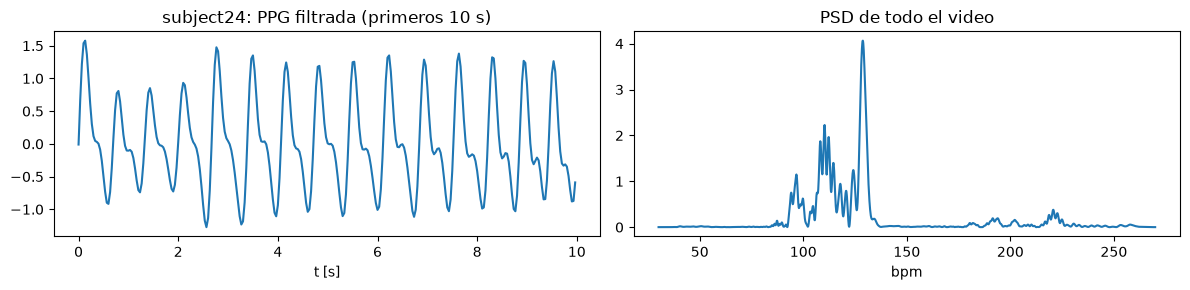

In [5]:
s = "subject24"
gt = ds.ground_truth(s)
u, y, _ = reference_hr(gt)
f, p = power_spectrum(y, FS, nfft=16384)
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].plot(u.t[:300], y[:300])
ax[0].set(title=f"{s}: PPG filtrada (primeros 10 s)", xlabel="t [s]")
band = (f > 0.5) & (f < 4.5)
ax[1].plot(60 * f[band], p[band])
ax[1].set(title="PSD de todo el video", xlabel="bpm")
plt.tight_layout()

## 3. Un frame de ejemplo

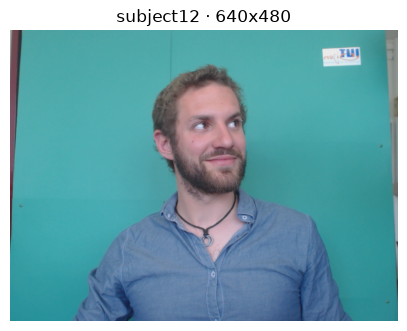

In [6]:
frame = next(ds.frames("subject12"))
plt.figure(figsize=(5, 4))
plt.imshow(frame)
plt.axis("off")
plt.title(f"subject12 · {frame.shape[1]}x{frame.shape[0]}");